
# Maximum Likelihood Estimation with Real Financial Data

We will use **daily S&P 500 closing prices** from the Federal Reserve Economic Data (FRED) database.

Our goal is to estimate the distribution of daily market returns.

If \(P_t\) denotes the S&P 500 closing value on day \(t\), define the daily log-return

$$
R_t = \log\left(\frac{P_t}{P_{t-1}}\right).
$$

As a first statistical model, assume

$$
R_t \overset{\text{iid}}{\sim} \mathcal N(\mu,\sigma^2).
$$

Given observed returns \(r_1,\ldots,r_n\), the likelihood is

$$
L(\mu,\sigma^2)
=
\prod_{i=1}^n
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left[
-\frac{(r_i-\mu)^2}{2\sigma^2}
\right].
$$

The MLEs are

$$
\hat\mu_{\rm MLE}
=
\frac1n\sum_{i=1}^n r_i,
$$

and

$$
\hat\sigma^2_{\rm MLE}
=
\frac1n\sum_{i=1}^n(r_i-\hat\mu)^2.
$$

Notice carefully that the MLE for \(\sigma^2\) uses \(1/n\), not \(1/(n-1)\).


In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# FRED daily S&P 500 series.
# The date range can be changed if desired.
url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=SP500&cosd=2024-01-01&coed=2026-10-05"
)

df = pd.read_csv(url)

df.head()


,observation_date,SP500
0,2024-01-02,4742.83
1,2024-01-03,4704.81
2,2024-01-04,4688.68
3,2024-01-05,4697.24
4,2024-01-08,4763.54



## 1. Inspect the real price data


Number of trading days: 691
First date: 2024-01-02
Last date:  2026-10-02


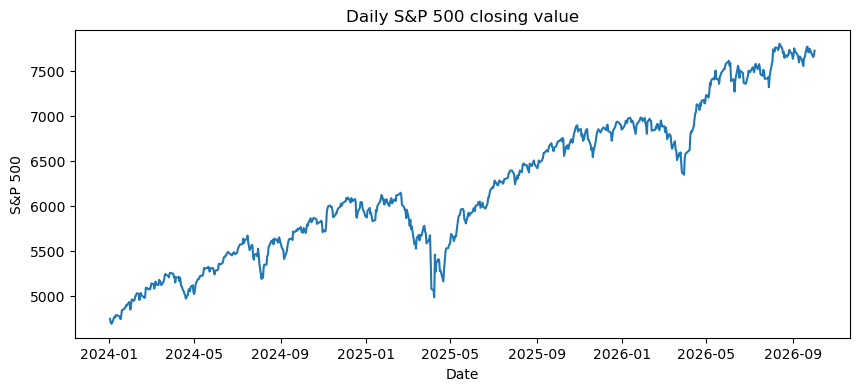

In [8]:

df["observation_date"] = pd.to_datetime(df["observation_date"])
df["SP500"] = pd.to_numeric(df["SP500"], errors="coerce")
df = df.dropna().reset_index(drop=True)

print(f"Number of trading days: {len(df)}")
print(f"First date: {df['observation_date'].iloc[0].date()}")
print(f"Last date:  {df['observation_date'].iloc[-1].date()}")

plt.figure(figsize=(10,4))
plt.plot(df["observation_date"], df["SP500"])
plt.xlabel("Date")
plt.ylabel("S&P 500")
plt.title("Daily S&P 500 closing value")
plt.show()



The price \(P_t\) itself is strongly time-dependent, so it is not sensible to model the prices as iid draws from a Gaussian distribution.

Instead, we work with **daily log-returns**

$$
R_t
=
\log\left(\frac{P_t}{P_{t-1}}\right).
$$


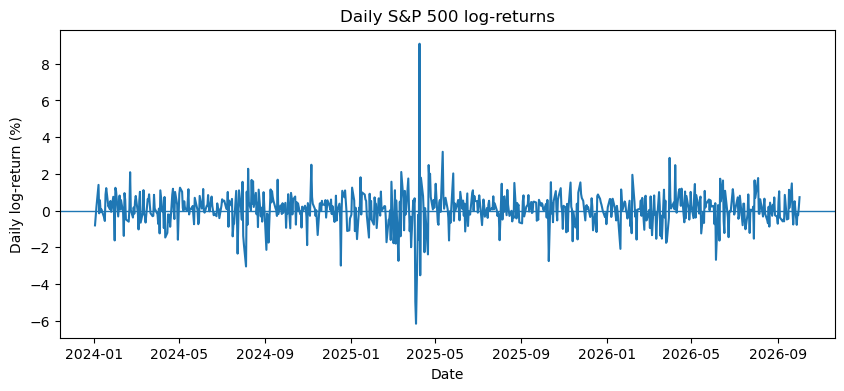

In [15]:

prices = df["SP500"].to_numpy()

returns = np.log(prices[1:] / prices[:-1])
dates = df["observation_date"].iloc[1:].to_numpy()

plt.figure(figsize=(10,4))
plt.plot(dates, 100*returns)
plt.axhline(0, linewidth=1)
plt.xlabel("Date")
plt.ylabel("Daily log-return (%)")
plt.title("Daily S&P 500 log-returns")
plt.show()



## 2. Fit a Gaussian model by maximum likelihood

Assume

$$
R_i\sim\mathcal N(\mu,\sigma^2).
$$

For the observed values \(r_1,\ldots,r_n\),

$$
\ell(\mu,\sigma^2)
=
-\frac{n}{2}\log(2\pi)
-\frac{n}{2}\log\sigma^2
-\frac{1}{2\sigma^2}
\sum_{i=1}^n(r_i-\mu)^2.
$$

Maximizing this log-likelihood gives

$$
\hat\mu_{\rm MLE}
=
\bar r,
$$

and

$$
\hat\sigma^2_{\rm MLE}
=
\frac1n
\sum_{i=1}^n(r_i-\bar r)^2.
$$


In [10]:

n = len(returns)

mu_hat = np.mean(returns)
sigma2_hat = np.mean((returns - mu_hat)**2)
sigma_hat = np.sqrt(sigma2_hat)

print(f"n = {n}")
print(f"mu_hat      = {mu_hat:.6f} per day")
print(f"sigma_hat   = {sigma_hat:.6f} per day")
print(f"sigma_hat   = {100*sigma_hat:.3f}% per day")
print(f"sigma2_hat  = {sigma2_hat:.8f}")


n = 690
mu_hat      = 0.000707 per day
sigma_hat   = 0.009564 per day
sigma_hat   = 0.956% per day
sigma2_hat  = 0.00009147



The fitted parameter

$$
\hat\sigma
$$

has a direct interpretation: it is the estimated **daily market volatility** under this model.

For example, if

$$
\hat\sigma = 0.012,
$$

then the estimated daily standard deviation of returns is approximately

$$
1.2\%.
$$



## 3. Compare the fitted probability model with the data

MLE tells us which Gaussian distribution best fits the observed returns **within the Gaussian family**.

It does **not** tell us that the Gaussian model is correct.

We should therefore compare

$$
\mathcal N(\hat\mu,\hat\sigma^2)
$$

with the empirical distribution of the observed returns.


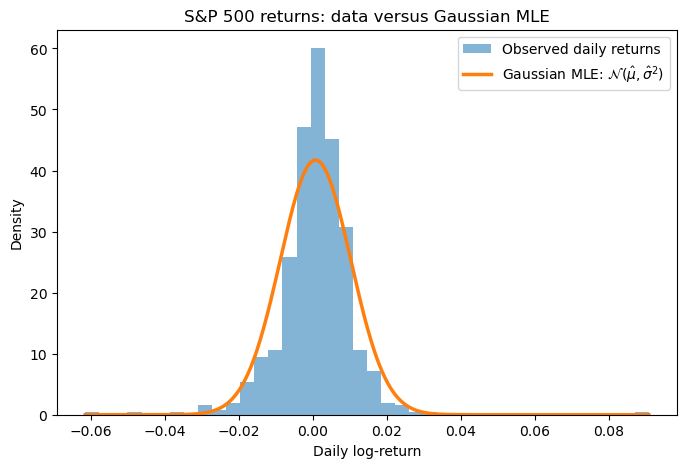

In [19]:

x = np.linspace(returns.min(), returns.max(), 500)
pdf = norm.pdf(x, loc=mu_hat, scale=sigma_hat)

plt.figure(figsize=(8,5))
plt.hist(
    returns,
    bins=40,
    density=True,
    alpha=0.55,
    label="Observed daily returns"
)
plt.plot(
    x,
    pdf,
    linewidth=2.5,
    label=r"Gaussian MLE: $\mathcal{N}(\hat\mu,\hat\sigma^2)$"
)

plt.xlabel("Daily log-return")
plt.ylabel("Density")
plt.title("S&P 500 returns: data versus Gaussian MLE")
plt.legend()
plt.show()



### What should we notice?

The Gaussian MLE gives us a compact model with two estimated parameters,

$$
(\hat\mu,\hat\sigma^2).
$$

But financial returns often exhibit unusually large positive and negative fluctuations.

This gives an important statistical lesson:

$$
\boxed{
\text{MLE finds the best parameter values inside the model we chose.}
}
$$

It does **not** guarantee that the chosen probability model itself is a good description of reality.



## 4. How uncertain is our estimate of the mean return?

Under the Gaussian model,

$$
\hat\mu=\bar R
\sim
\mathcal N\left(
\mu,\frac{\sigma^2}{n}
\right).
$$

Therefore,

$$
\operatorname{SE}(\hat\mu)
=
\frac{\sigma}{\sqrt n}.
$$

Since \(\sigma\) is unknown, we use the fitted value:

$$
\widehat{\operatorname{SE}}(\hat\mu)
=
\frac{\hat\sigma}{\sqrt n}.
$$


In [12]:

se_mu = sigma_hat / np.sqrt(n)

print(f"mu_hat = {mu_hat:.6f}")
print(f"Estimated SE(mu_hat) = {se_mu:.6f}")


mu_hat = 0.000707
Estimated SE(mu_hat) = 0.000364



## 5. Parametric bootstrap for market volatility

Now suppose we want to understand the uncertainty in

$$
\hat\sigma^2.
$$

We can use the parametric bootstrap.

Treat

$$
\mathcal N(\hat\mu,\hat\sigma^2)
$$

as the fitted model, simulate repeated datasets from it, and recompute the MLE each time:

$$
R_1^*,\ldots,R_n^*
\sim
\mathcal N(\hat\mu,\hat\sigma^2).
$$

For every simulated dataset, compute

$$
\hat\sigma^{2*}
=
\frac1n
\sum_{i=1}^n
(R_i^*-\bar R^*)^2.
$$

Repeating this gives an approximate sampling distribution for the estimated volatility.


In [13]:

rng = np.random.default_rng(7)

B = 5000
sigma2_boot = np.empty(B)

for b in range(B):
    r_star = rng.normal(
        loc=mu_hat,
        scale=sigma_hat,
        size=n
    )

    mu_star = np.mean(r_star)
    sigma2_boot[b] = np.mean((r_star - mu_star)**2)

boot_se_sigma2 = np.std(sigma2_boot, ddof=1)

print(f"Observed sigma^2 MLE = {sigma2_hat:.8f}")
print(f"Bootstrap SE         = {boot_se_sigma2:.8f}")


Observed sigma^2 MLE = 0.00009147
Bootstrap SE         = 0.00000488


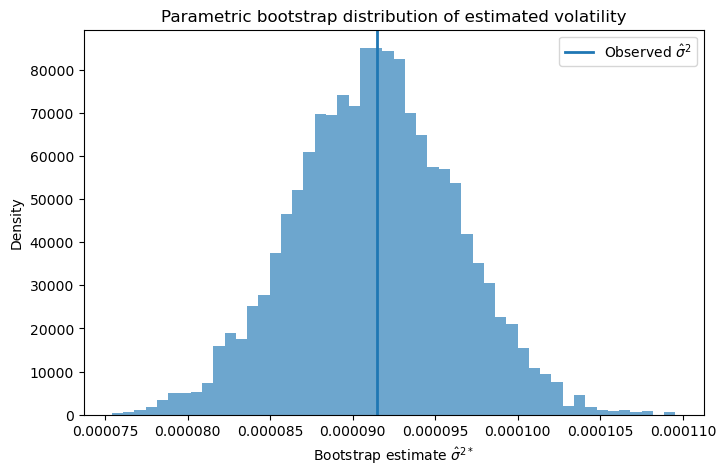

In [14]:

plt.figure(figsize=(8,5))

plt.hist(
    sigma2_boot,
    bins=50,
    density=True,
    alpha=0.65
)

plt.axvline(
    sigma2_hat,
    linewidth=2,
    label=r"Observed $\hat{\sigma}^2$"
)

plt.xlabel(r"Bootstrap estimate $\hat{\sigma}^{2*}$")
plt.ylabel("Density")
plt.title("Parametric bootstrap distribution of estimated volatility")
plt.legend()
plt.show()



## Main statistical message

From one real financial dataset we have now performed the complete estimation workflow:

$$
\boxed{
\text{market prices}
\rightarrow
\text{returns}
\rightarrow
\text{probability model}
\rightarrow
\text{MLE}
\rightarrow
\text{parameter uncertainty}
}
$$

Specifically,

$$
P_t
\rightarrow
R_t
\rightarrow
R_t\sim\mathcal N(\mu,\sigma^2)
\rightarrow
(\hat\mu,\hat\sigma^2)
\rightarrow
\text{bootstrap uncertainty}.
$$

The key distinction is

$$
\boxed{
\text{MLE estimates the parameters of the chosen model;
it does not validate the model itself.}
}
$$
